In [101]:
import pandas as pd
import nltk

from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import cv2
import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import detrend
from statsmodels.tsa.seasonal import seasonal_decompose

# ZADANIE 1

In [102]:


df = pd.read_csv("data/stroke-dataset.csv")
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [103]:
# Ujednolicenie nazw kolumn źródłowych (zbiór może zawierać 'age'/'Age' oraz 'bmi'/'BMI')
rename_map = {c: c.lower() for c in df.columns if c.lower() in ("age", "bmi")}
df = df.rename(columns=rename_map)

# Upewnienie się, że kolumny są numeryczne (np. 'N/A' zostanie zamienione na NaN)
df["age"] = pd.to_numeric(df["age"], errors="coerce")
df["bmi"] = pd.to_numeric(df["bmi"], errors="coerce")

print("Liczba wierszy i kolumn:", df.shape)
print()
print("Braki danych w kolumnach źródłowych:")
print(df[["age", "bmi"]].isna().sum())
print()
df[["age", "bmi"]].describe()

Liczba wierszy i kolumn: (5110, 12)

Braki danych w kolumnach źródłowych:
age      0
bmi    201
dtype: int64



,age,bmi
count,5110.000000,4909.000000
mean,43.226614,28.893237
std,22.612647,7.854067
min,0.080000,10.300000
25%,25.000000,23.500000
50%,45.000000,28.100000
75%,61.000000,33.100000
max,82.000000,97.600000


In [104]:
# Uzupełnienie ewentualnych braków (jeśli nie zostały obsłużone w Laboratorium 2)
if df["bmi"].isna().any():
    df["bmi"] = df["bmi"].fillna(df["bmi"].median())
if df["age"].isna().any():
    df["age"] = df["age"].fillna(df["age"].median())

print(df[["age", "bmi"]].isna().sum())

age    0
bmi    0
dtype: int64


In [105]:
df["AgeGroup"] = pd.cut(
    df["age"],
    bins=[0, 18, 31, 65, np.inf],
    labels=["Child", "YoungAdult", "Adult", "Senior"],
    right=False
)

df[["age", "AgeGroup"]].head(10)

,age,AgeGroup
0,67.0,Senior
1,61.0,Adult
2,80.0,Senior
3,49.0,Adult
4,79.0,Senior
5,81.0,Senior
6,74.0,Senior
7,69.0,Senior
8,59.0,Adult
9,78.0,Senior


In [106]:
df["BMICategory"] = pd.cut(
    df["bmi"],
    bins=[0, 18.5, 25, 30, np.inf],
    labels=["Underweight", "NormalWeight", "Overweight", "Obese"],
    right=False
)

df[["bmi", "BMICategory"]].head(10)

,bmi,BMICategory
0,36.6,Obese
1,28.1,Overweight
2,32.5,Obese
3,34.4,Obese
4,24.0,NormalWeight
5,29.0,Overweight
6,27.4,Overweight
7,22.8,NormalWeight
8,28.1,Overweight
9,24.2,NormalWeight


In [107]:
age_counts = df["AgeGroup"].value_counts().sort_index()
bmi_counts = df["BMICategory"].value_counts().sort_index()

print("Liczba pacjentów w grupach wiekowych:")
print(age_counts)
print()
print("Liczba pacjentów w kategoriach BMI:")
print(bmi_counts)
print()
print("Pacjenci bez przypisanej grupy (NaN):",
      df["AgeGroup"].isna().sum(), "(wiek),", df["BMICategory"].isna().sum(), "(BMI)")

Liczba pacjentów w grupach wiekowych:
AgeGroup
Child          856
YoungAdult     714
Adult         2513
Senior        1027
Name: count, dtype: int64

Liczba pacjentów w kategoriach BMI:
BMICategory
Underweight      337
NormalWeight    1243
Overweight      1610
Obese           1920
Name: count, dtype: int64

Pacjenci bez przypisanej grupy (NaN): 0 (wiek), 0 (BMI)


In [108]:
print("Typy nowych kolumn:")
print(df[["AgeGroup", "BMICategory"]].dtypes)
print()
df.head()

Typy nowych kolumn:
AgeGroup       category
BMICategory    category
dtype: object



,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke,AgeGroup,BMICategory
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1,Senior,Obese
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.1,never smoked,1,Adult,Overweight
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1,Senior,Obese
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1,Adult,Obese
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1,Senior,NormalWeight


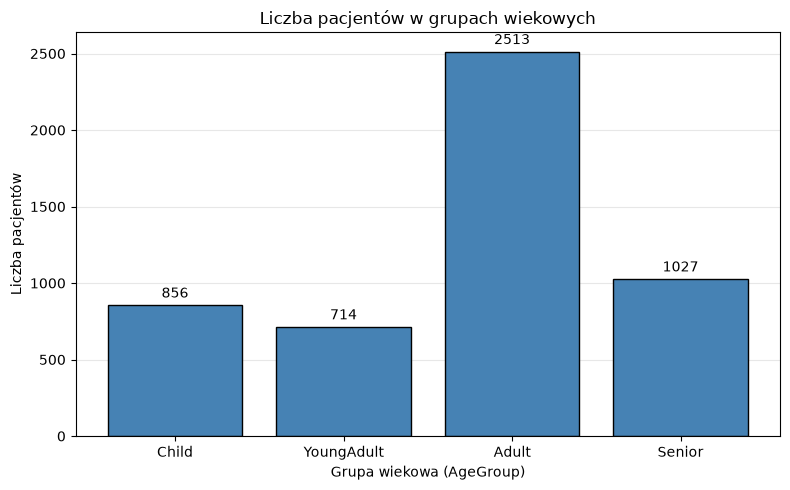

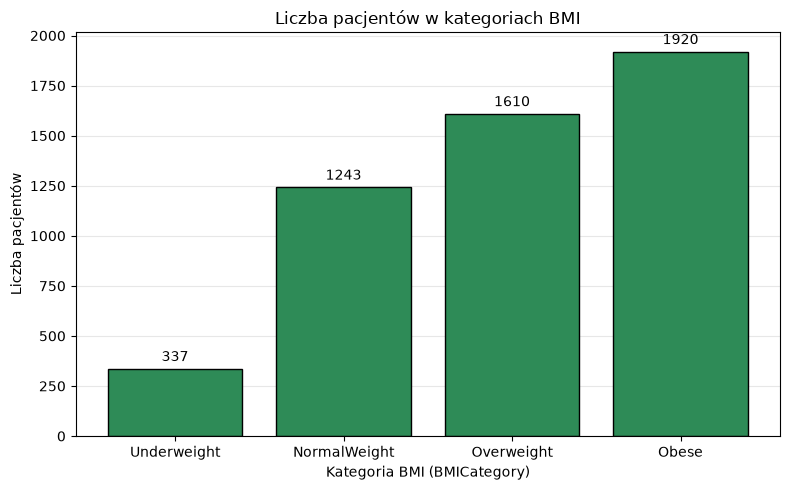

In [109]:
def bar_counts(counts, title, xlabel, color):
    fig, ax = plt.subplots(figsize=(8, 5))
    bars = ax.bar(counts.index.astype(str), counts.values, color=color, edgecolor="black")
    ax.bar_label(bars, padding=3)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Liczba pacjentów")
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.show()

bar_counts(age_counts, "Liczba pacjentów w grupach wiekowych", "Grupa wiekowa (AgeGroup)", "steelblue")
bar_counts(bmi_counts, "Liczba pacjentów w kategoriach BMI", "Kategoria BMI (BMICategory)", "seagreen")

Odsetek pacjentów z udarem [%] wg AgeGroup:
AgeGroup
Child          0.23
YoungAdult     0.00
Adult          3.50
Senior        15.48
Name: stroke, dtype: float64

Odsetek pacjentów z udarem [%] wg BMICategory:
BMICategory
Underweight     0.30
NormalWeight    2.82
Overweight      7.14
Obese           5.10
Name: stroke, dtype: float64



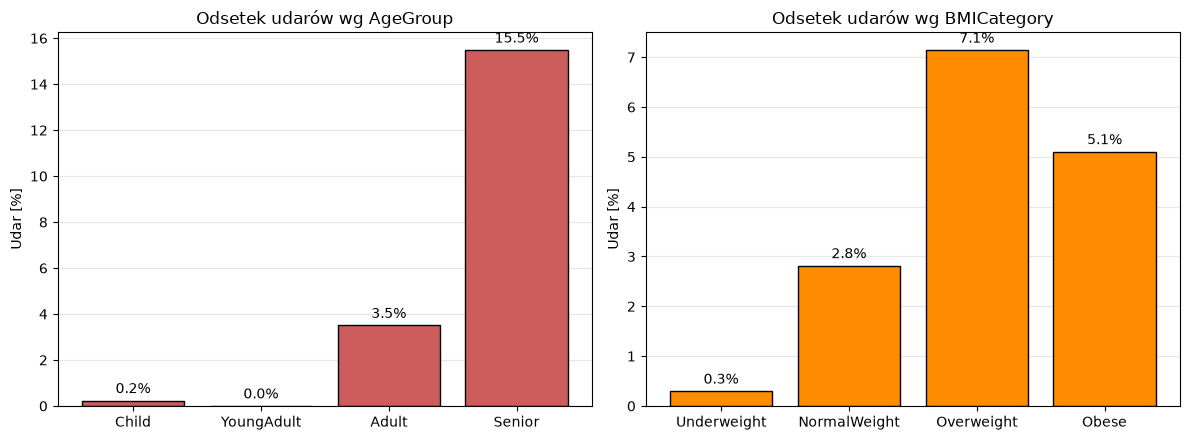

In [110]:
if "stroke" in df.columns:
    for col in ["AgeGroup", "BMICategory"]:
        rate = (df.groupby(col, observed=True)["stroke"].mean() * 100).round(2)
        print(f"Odsetek pacjentów z udarem [%] wg {col}:")
        print(rate)
        print()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, col, color in zip(axes, ["AgeGroup", "BMICategory"], ["indianred", "darkorange"]):
        rate = df.groupby(col, observed=True)["stroke"].mean() * 100
        bars = ax.bar(rate.index.astype(str), rate.values, color=color, edgecolor="black")
        ax.bar_label(bars, fmt="%.1f%%", padding=3)
        ax.set_title(f"Odsetek udarów wg {col}")
        ax.set_ylabel("Udar [%]")
        ax.grid(axis="y", alpha=0.3)
        ax.set_axisbelow(True)
    plt.tight_layout()
    plt.show()
else:
    print("W zbiorze nie ma kolumny 'stroke' – pominięto analizę odsetka udarów.")

# Zadanie 2

In [111]:
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt_tab')

df = pd.read_csv("data/reddit-data.csv")

df.head()

[nltk_data] Downloading package punkt to /home/xxxwi/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /home/xxxwi/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /home/xxxwi/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /home/xxxwi/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to /home/xxxwi/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


,clean_comment,category
0,family mormon have never tried explain them t...,1
1,buddhism has very much lot compatible with chr...,1
2,seriously don say thing first all they won get...,-1
3,what you have learned yours and only yours wha...,0
4,for your own benefit you may want read living ...,1


In [112]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 37249 entries, 0 to 37248
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   clean_comment  37149 non-null  str  
 1   category       37249 non-null  int64
dtypes: int64(1), str(1)
memory usage: 582.1 KB


In [113]:
df.isnull().sum()

clean_comment    100
category           0
dtype: int64

In [114]:
df = df.dropna()
df.isnull().sum()

clean_comment    0
category         0
dtype: int64

In [115]:
text_column = df.columns[0]
df[text_column] = df[text_column].astype(str)
tokens = df[text_column].apply(word_tokenize)
tokens.head()

0    [family, mormon, have, never, tried, explain, ...
1    [buddhism, has, very, much, lot, compatible, w...
2    [seriously, don, say, thing, first, all, they,...
3    [what, you, have, learned, yours, and, only, y...
4    [for, your, own, benefit, you, may, want, read...
Name: clean_comment, dtype: object

In [116]:
stemmer = PorterStemmer()
stems = tokens.apply(lambda x: [stemmer.stem(word) for word in x])
stems.head()

0    [famili, mormon, have, never, tri, explain, th...
1    [buddhism, ha, veri, much, lot, compat, with, ...
2    [serious, don, say, thing, first, all, they, w...
3    [what, you, have, learn, your, and, onli, your...
4    [for, your, own, benefit, you, may, want, read...
Name: clean_comment, dtype: object

In [117]:
lemmatizer = WordNetLemmatizer()
lemmas = tokens.apply(lambda x: [lemmatizer.lemmatize(word) for word in x])
lemmas.head()

0    [family, mormon, have, never, tried, explain, ...
1    [buddhism, ha, very, much, lot, compatible, wi...
2    [seriously, don, say, thing, first, all, they,...
3    [what, you, have, learned, yours, and, only, y...
4    [for, your, own, benefit, you, may, want, read...
Name: clean_comment, dtype: object

In [118]:
stop_words = set(stopwords.words('english'))
filtered = tokens.apply(
    lambda x: [word for word in x if word.lower() not in stop_words]
)
filtered.head()

0    [family, mormon, never, tried, explain, still,...
1    [buddhism, much, lot, compatible, christianity...
2    [seriously, say, thing, first, get, complex, e...
3    [learned, want, teach, different, focus, goal,...
4    [benefit, may, want, read, living, buddha, liv...
Name: clean_comment, dtype: object

# Zadanie 3

(512, 773, 3)


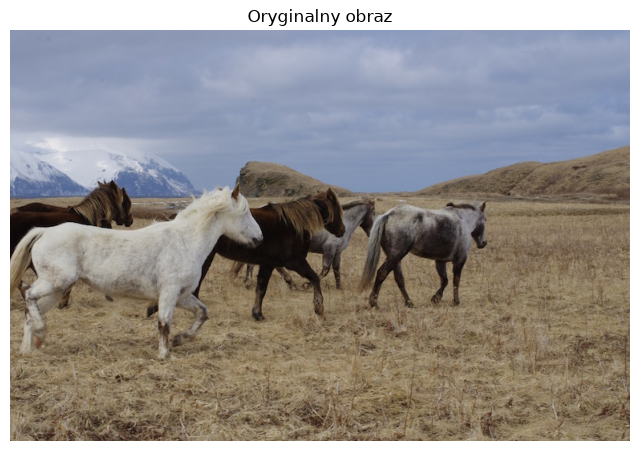

In [119]:
image = cv2.imread("data/horses.jpg")
if image is None:
    raise FileNotFoundError("Nie znaleziono pliku horses.jpg")
print(image.shape)

plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Oryginalny obraz")
plt.axis("off")
plt.show()


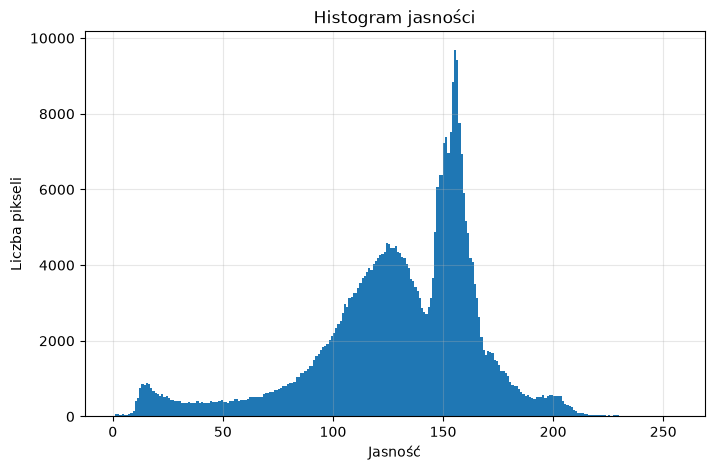

In [120]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
 
plt.figure(figsize=(8, 5))
plt.hist(gray.ravel(), bins=256, range=(0, 256))
plt.title("Histogram jasności")
plt.xlabel("Jasność")
plt.ylabel("Liczba pikseli")
plt.grid(True, alpha=0.3)
plt.show()


In [121]:
sobelx = cv2.Sobel(gray, cv2.CV_64F, 1, 0)
sobely = cv2.Sobel(gray, cv2.CV_64F, 0, 1)
sobel = cv2.magnitude(sobelx, sobely)
 
# %% 6. Operator Prewitta
kernelx = np.array([[1, 0, -1],
                    [1, 0, -1],
                    [1, 0, -1]])
kernely = np.array([[1, 1, 1],
                    [0, 0, 0],
                    [-1, -1, -1]])
 
prewittx = cv2.filter2D(gray, cv2.CV_64F, kernelx)
prewitty = cv2.filter2D(gray, cv2.CV_64F, kernely)
prewitt = cv2.magnitude(prewittx, prewitty)


In [122]:
kernelx = np.array([[1, 0],
                    [0, -1]])
kernely = np.array([[0, 1],
                    [-1, 0]])
robertsx = cv2.filter2D(gray, cv2.CV_64F, kernelx)
robertsy = cv2.filter2D(gray, cv2.CV_64F, kernely)
roberts = cv2.magnitude(robertsx, robertsy)
 


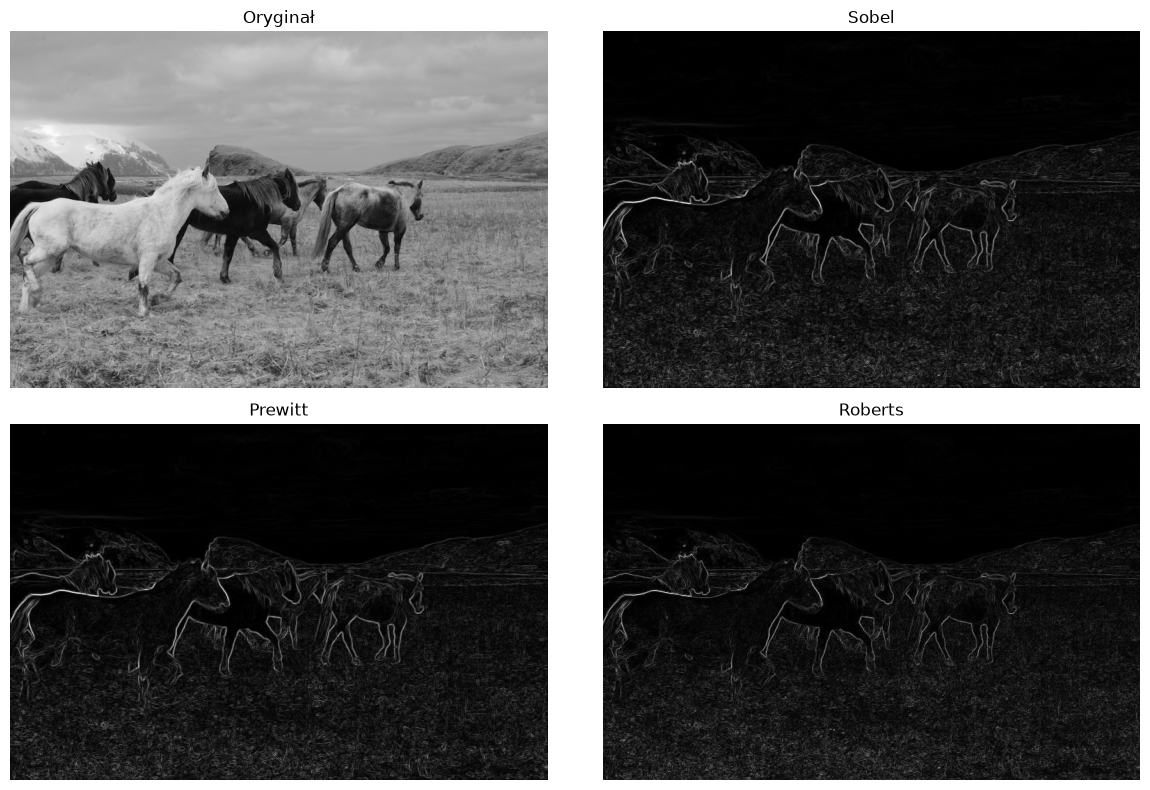

In [123]:
titles = ["Oryginał", "Sobel", "Prewitt", "Roberts"]
images = [gray, sobel, prewitt, roberts]
 
plt.figure(figsize=(12, 8))
for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")
plt.tight_layout()
plt.show()


# Zadanie 4

In [124]:
df = pd.read_csv("data/airline-passengers.csv", parse_dates=["Month"])
df = df.sort_values("Month").reset_index(drop=True)

df.head()

,Month,Passengers
0,1949-01-01,112
1,1949-02-01,118
2,1949-03-01,132
3,1949-04-01,129
4,1949-05-01,121


In [125]:
df.info()



<class 'pandas.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Month       144 non-null    datetime64[us]
 1   Passengers  144 non-null    int64         
dtypes: datetime64[us](1), int64(1)
memory usage: 2.4 KB


In [126]:
df.isna().sum()

Month         0
Passengers    0
dtype: int64

In [127]:
pd.Series({"Powtórzone miesiące": df["Month"].duplicated().sum()})

Powtórzone miesiące    0
dtype: int64

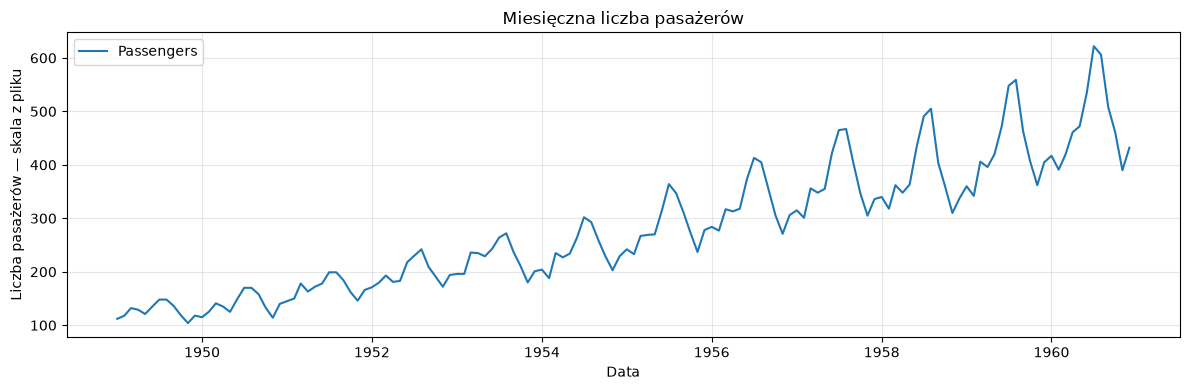

In [128]:
szereg = df.set_index("Month")["Passengers"].asfreq("MS")

if szereg.isna().any() or (szereg <= 0).any():
    raise ValueError("Szereg musi być kompletny i zawierać dodatnie wartości.")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(szereg.index, szereg, label="Passengers")
ax.set_title("Miesięczna liczba pasażerów")
ax.set_xlabel("Data")
ax.set_ylabel("Liczba pasażerów — skala z pliku")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [129]:
statystyki = pd.Series({
    "Średnia": szereg.mean(),
    "Maksimum": szereg.max(),
    "Minimum": szereg.min(),
    "Wariancja z próby": szereg.var(ddof=1),
    "Odchylenie standardowe z próby": szereg.std(ddof=1),
    "Mediana": szereg.median()
}, name="Wartość")

kwartyle = szereg.quantile([0.25, 0.50, 0.75])
kwartyle.index = ["Q1 — 25%", "Q2 — 50%", "Q3 — 75%"]
kwartyle.name = "Wartość"

statystyki.to_frame()


,Wartość
Średnia,280.298611
Maksimum,622.000000
Minimum,104.000000
Wariancja z próby,14391.917201
Odchylenie standardowe z próby,119.966317
Mediana,265.500000


In [130]:
kwartyle.to_frame()

,Wartość
Q1 — 25%,180.0
Q2 — 50%,265.5
Q3 — 75%,360.5


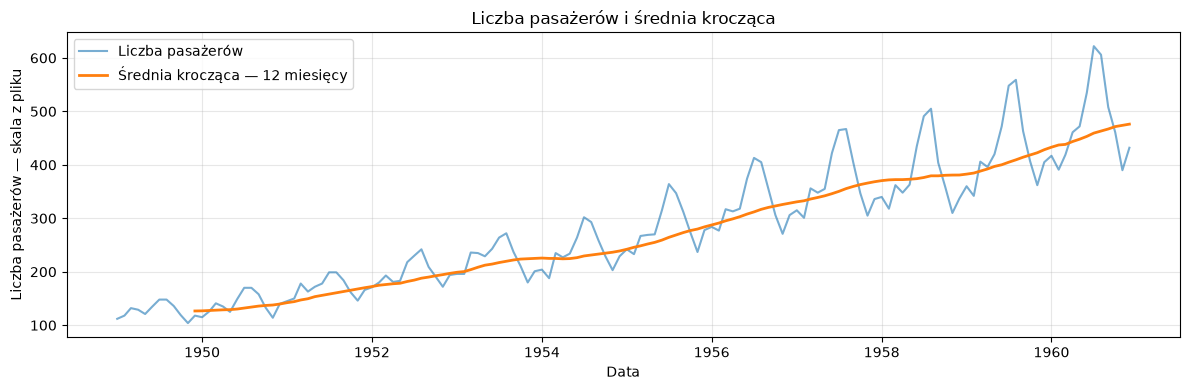

In [131]:
cechy = szereg.to_frame()
cechy["Srednia_kroczaca_12"] = szereg.rolling(window=12, min_periods=12).mean()



fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(szereg.index, szereg, label="Liczba pasażerów", alpha=0.6)
ax.plot(cechy.index, cechy["Srednia_kroczaca_12"], label="Średnia krocząca — 12 miesięcy", linewidth=2)
ax.set_title("Liczba pasażerów i średnia krocząca")
ax.set_xlabel("Data")
ax.set_ylabel("Liczba pasażerów — skala z pliku")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


In [132]:
cechy[["Passengers", "Srednia_kroczaca_12"]].tail(12)

,Passengers,Srednia_kroczaca_12
Month,,
1960-01-01,417,433.083333
1960-02-01,391,437.166667
1960-03-01,419,438.250000
1960-04-01,461,443.666667
1960-05-01,472,448.000000
1960-06-01,535,453.250000
1960-07-01,622,459.416667
1960-08-01,606,463.333333
1960-09-01,508,467.083333


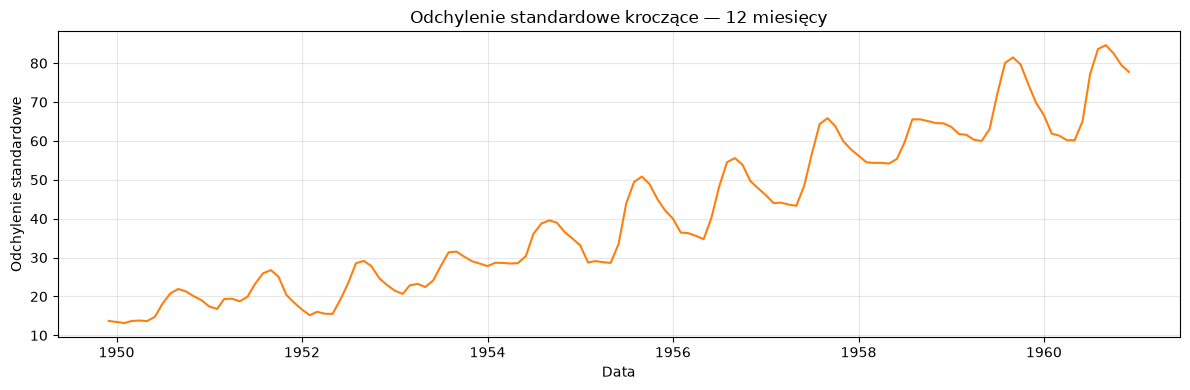

In [133]:
cechy["Odchylenie_kroczace_12"] = szereg.rolling(window=12, min_periods=12).std(ddof=1)



fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(cechy.index, cechy["Odchylenie_kroczace_12"], color="tab:orange")
ax.set_title("Odchylenie standardowe kroczące — 12 miesięcy")
ax.set_xlabel("Data")
ax.set_ylabel("Odchylenie standardowe")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [134]:
cechy[["Passengers", "Odchylenie_kroczace_12"]].tail(12)

,Passengers,Odchylenie_kroczace_12
Month,,
1960-01-01,417,66.624399
1960-02-01,391,61.866180
1960-03-01,419,61.382741
1960-04-01,461,60.171472
1960-05-01,472,60.184565
1960-06-01,535,65.021849
1960-07-01,622,77.194510
1960-08-01,606,83.630500
1960-09-01,508,84.617276


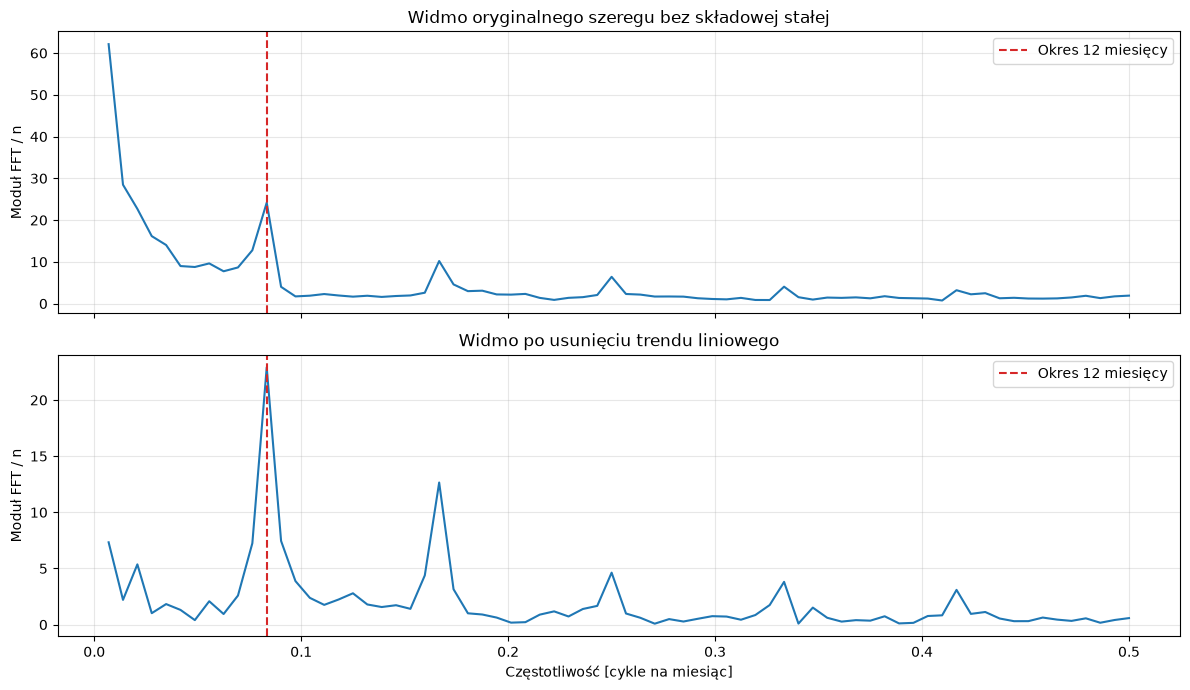

In [135]:
wartosci = szereg.to_numpy(dtype=float)
liczba_obserwacji = len(wartosci)
czestotliwosci = np.fft.rfftfreq(liczba_obserwacji, d=1.0)

transformata = np.fft.rfft(wartosci)
wartosci_bez_trendu = detrend(wartosci, type="linear")
transformata_bez_trendu = np.fft.rfft(wartosci_bez_trendu)

okresy = np.full(czestotliwosci.shape, np.nan)
np.divide(1.0, czestotliwosci, out=okresy, where=czestotliwosci > 0)

widmo = pd.DataFrame({
    "Czestotliwosc_cykle_na_miesiac": czestotliwosci,
    "Okres_miesiace": okresy,
    "Czesc_rzeczywista_FFT": transformata.real,
    "Czesc_urojona_FFT": transformata.imag,
    "Modul_FFT_przez_n": np.abs(transformata) / liczba_obserwacji,
    "Modul_FFT_bez_trendu_przez_n": np.abs(transformata_bez_trendu) / liczba_obserwacji
})

widmo.head(10)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

for ax, kolumna, tytul in [
    (axes[0], "Modul_FFT_przez_n", "Widmo oryginalnego szeregu bez składowej stałej"),
    (axes[1], "Modul_FFT_bez_trendu_przez_n", "Widmo po usunięciu trendu liniowego")
]:
    ax.plot(czestotliwosci[1:], widmo[kolumna].iloc[1:])
    ax.axvline(1 / 12, color="tab:red", linestyle="--", label="Okres 12 miesięcy")
    ax.set_title(tytul)
    ax.set_ylabel("Moduł FFT / n")
    ax.grid(alpha=0.3)
    ax.legend()

axes[1].set_xlabel("Częstotliwość [cykle na miesiąc]")
plt.tight_layout()
plt.show()


In [136]:
widmo.iloc[1:].nlargest(5, "Modul_FFT_bez_trendu_przez_n")

,Czestotliwosc_cykle_na_miesiac,Okres_miesiace,Czesc_rzeczywista_FFT,Czesc_urojona_FFT,Modul_FFT_przez_n,Modul_FFT_bez_trendu_przez_n
12,0.083333,12.000000,-3466.756579,321.351942,24.177907,22.908963
24,0.166667,6.000000,1207.000000,-836.580540,10.198446,12.652241
13,0.090278,11.076923,-426.820112,-390.162761,4.015801,7.449394
1,0.006944,144.000000,855.032345,8906.559578,62.135466,7.329799
11,0.076389,13.090909,-238.673364,1823.933094,12.774186,7.244163


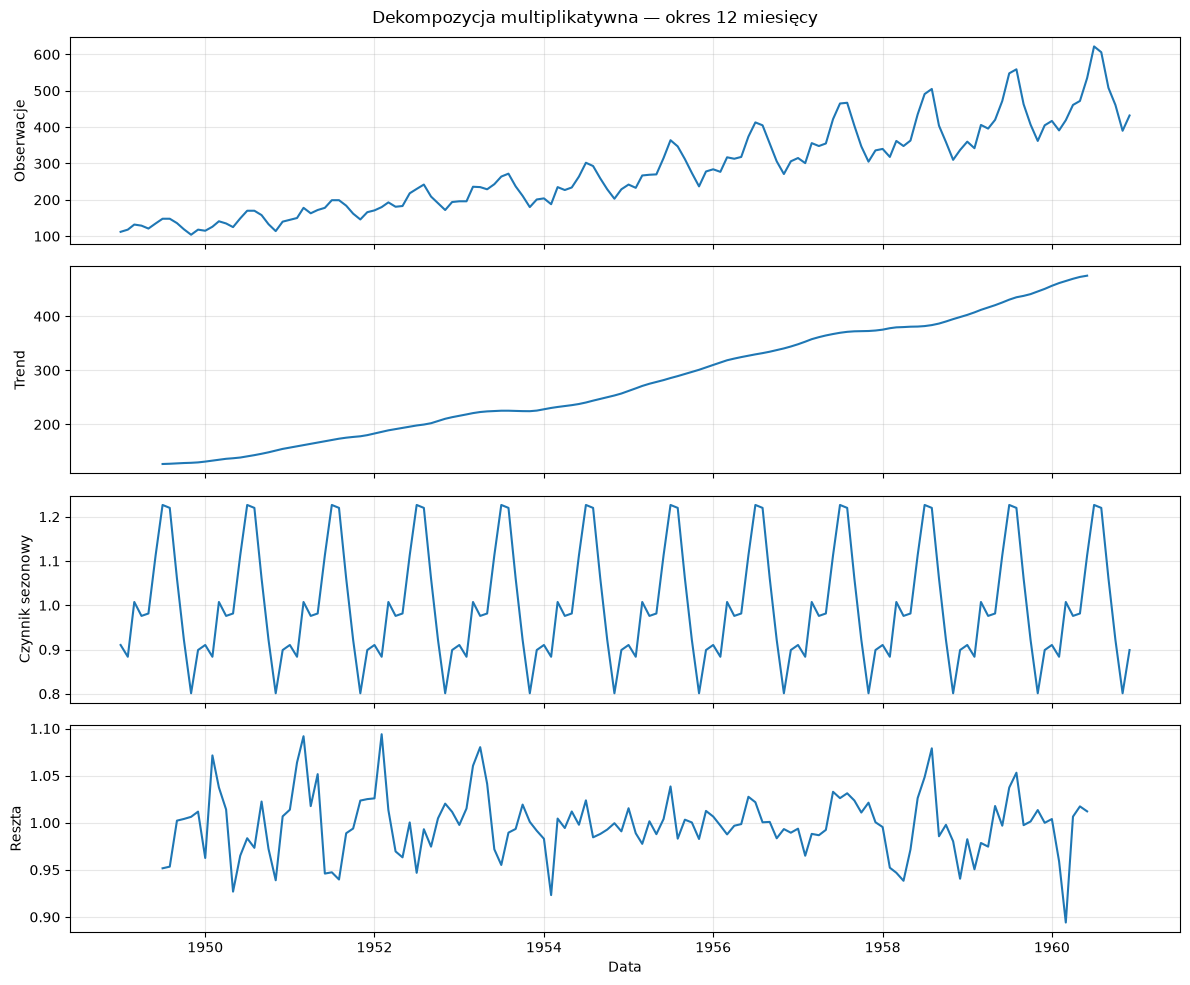

In [137]:
dekompozycja = seasonal_decompose(szereg, model="multiplicative", period=12)

cechy["Trend"] = dekompozycja.trend
cechy["Czynnik_sezonowy"] = dekompozycja.seasonal
cechy["Reszta"] = dekompozycja.resid

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)

for ax, skladnik, etykieta in [
    (axes[0], dekompozycja.observed, "Obserwacje"),
    (axes[1], dekompozycja.trend, "Trend"),
    (axes[2], dekompozycja.seasonal, "Czynnik sezonowy"),
    (axes[3], dekompozycja.resid, "Reszta")
]:
    ax.plot(skladnik.index, skladnik)
    ax.set_ylabel(etykieta)
    ax.grid(alpha=0.3)

fig.suptitle("Dekompozycja multiplikatywna — okres 12 miesięcy")
axes[-1].set_xlabel("Data")
plt.tight_layout()
plt.show()


In [138]:
cechy.head(15)



,Passengers,Srednia_kroczaca_12,Odchylenie_kroczace_12,Trend,Czynnik_sezonowy,Reszta
Month,,,,,,
1949-01-01,112,NaN,NaN,NaN,0.910230,NaN
1949-02-01,118,NaN,NaN,NaN,0.883625,NaN
1949-03-01,132,NaN,NaN,NaN,1.007366,NaN
1949-04-01,129,NaN,NaN,NaN,0.975906,NaN
1949-05-01,121,NaN,NaN,NaN,0.981378,NaN
1949-06-01,135,NaN,NaN,NaN,1.112776,NaN
1949-07-01,148,NaN,NaN,126.791667,1.226556,0.951664
1949-08-01,148,NaN,NaN,127.250000,1.219911,0.953401
1949-09-01,136,NaN,NaN,127.958333,1.060492,1.002220


In [139]:
cechy.tail(15)

,Passengers,Srednia_kroczaca_12,Odchylenie_kroczace_12,Trend,Czynnik_sezonowy,Reszta
Month,,,,,,
1959-10-01,407,418.333333,79.680422,440.958333,0.921757,1.001337
1959-11-01,362,422.666667,74.498729,445.833333,0.801178,1.013461
1959-12-01,405,428.333333,69.830097,450.625000,0.898824,0.999919
1960-01-01,417,433.083333,66.624399,456.333333,0.910230,1.003928
1960-02-01,391,437.166667,61.866180,461.375000,0.883625,0.959079
1960-03-01,419,438.250000,61.382741,465.208333,1.007366,0.894086
1960-04-01,461,443.666667,60.171472,469.333333,0.975906,1.006495
1960-05-01,472,448.000000,60.184565,472.750000,0.981378,1.017359
1960-06-01,535,453.250000,65.021849,475.041667,1.112776,1.012079


# Zadanie 5

In [140]:
df = pd.read_csv("data/wine.csv")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [141]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [143]:
X = df.drop(columns=["quality"])
y = df["quality"]

In [145]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

df_pca = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

df_pca.head()

,PC1,PC2
0,-1.078814,1.033899
1,-0.307332,2.289875
2,-0.265776,1.348870
3,2.617729,-0.099643
4,-1.080670,1.032473


Udział wyjaśnionej wariancji:
PC1: 0.2719 (27.19%)
PC2: 0.1587 (15.87%)
Łącznie: 0.4307 (43.07%)


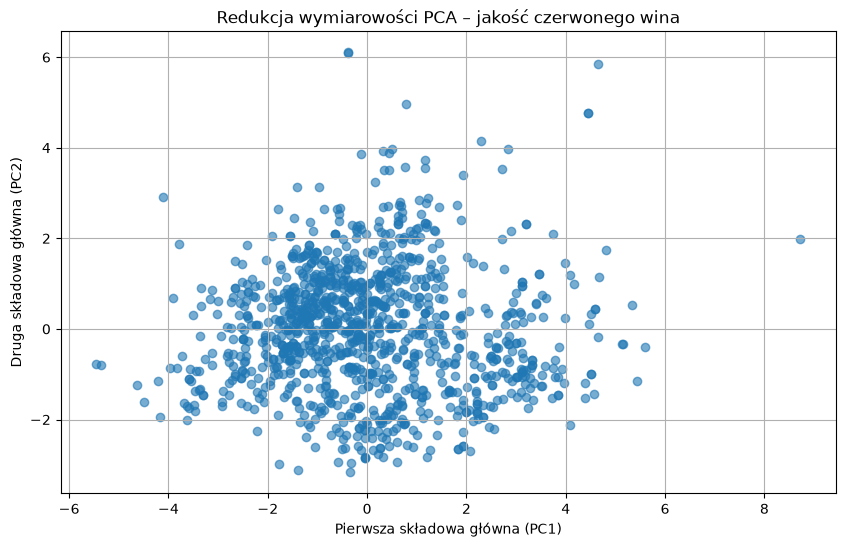

In [147]:
explained_variance = pca.explained_variance_ratio_

print("Udział wyjaśnionej wariancji:")
print(f"PC1: {explained_variance[0]:.4f} ({explained_variance[0] * 100:.2f}%)")
print(f"PC2: {explained_variance[1]:.4f} ({explained_variance[1] * 100:.2f}%)")
print(f"Łącznie: {explained_variance.sum():.4f} ({explained_variance.sum() * 100:.2f}%)")

plt.figure(figsize=(10, 6))
plt.scatter(df_pca["PC1"], df_pca["PC2"], alpha=0.6)
plt.xlabel("Pierwsza składowa główna (PC1)")
plt.ylabel("Druga składowa główna (PC2)")
plt.title("Redukcja wymiarowości PCA – jakość czerwonego wina")
plt.grid(True)
plt.show()

In [149]:
components = pd.DataFrame(
    pca.components_,
    columns=X.columns,
    index=["PC1", "PC2"]
)

components

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,Id
PC1,0.476593,-0.204295,0.437978,0.168989,0.219808,-0.050271,0.025591,0.409653,-0.417033,0.227146,-0.140103,-0.215143
PC2,-0.114893,0.342102,-0.200551,0.217297,0.133251,0.455961,0.536663,0.231536,0.025853,-0.100847,-0.420557,-0.165373


In [150]:
total_variance = pca.explained_variance_ratio_.sum() * 100

print(
    f"Dwie pierwsze składowe główne wyjaśniają "
    f"{total_variance:.2f}% całkowitej wariancji danych."
)
print(
    f"Pozostałe {100 - total_variance:.2f}% wariancji "
    f"nie zostało zachowane w dwuwymiarowej reprezentacji."
)

Dwie pierwsze składowe główne wyjaśniają 43.07% całkowitej wariancji danych.
Pozostałe 56.93% wariancji nie zostało zachowane w dwuwymiarowej reprezentacji.
